<a href="https://colab.research.google.com/github/DavidDonoso1204/Proyecto_grupal_BIO218/blob/main/Proyecto_grupal_BIO218.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto Grupal Colaborativo — BIO 218**
## **Efecto de la hipoxia y de la recuperación sobre la expresión relativa de un gen diana (experimento simulado de qPCR)**

**Integrantes:** Castillo Jamel Alejandra, Castillo Ashly Marieth, De Gracia Yahelys, Donoso David Antonio, Gill Liz Denis, Castillo Francia.

## Problema biológico
Cuando baja el oxígeno disponible (hipoxia), las células modifican la expresión de genes relacionados con el metabolismo y la supervivencia, y una vía central en esa respuesta es la del factor inducible por hipoxia (HIF). En este experimento simulado de qPCR se midió la expresión relativa de un gen diana en muestras bajo normoxia, hipoxia y recuperación. El conjunto de datos no identifica el gen, por lo que no se le atribuye una función específica. Se desconoce si su expresión cambia entre estas condiciones, entre cuáles lo hace y qué tan grande es esa diferencia.

## **Pregunta de investigación**
¿Existe diferencia en la expresión relativa del gen diana entre las condiciones de normoxia, hipoxia y recuperación? Si es así, ¿entre qué condiciones se presentan estas diferencias, luego de analizar la distribución de los datos, aplicar una transformación logarítmica (log2) y registrar los criterios usados para limpiar los datos?

## **Hipótesis**
- **H₁:** al menos una condición tiene una media de expresión relativa, en escala log2(x), distinta de las demás.
- **H₀:** la media de la expresión relativa, en escala log2(x), es igual en las tres condiciones.

## **Variables**

| Variable | Tipo | Unidad | Papel |
|---|---|---|---|
| condicion_oxigeno | Cualitativa nominal (3 niveles: Normoxia, Hipoxia, Recuperación) | Sin unidad | Independiente |
| expresion_relativa | Cuantitativa continua (fold change; se analiza en log2(x)) | Razón, sin unidad | Dependiente |
| Ct_target, Ct_housekeeping, viabilidad_pct | Cuantitativas continuas | Ciclos (Ct) y % | Apoyo (control de calidad) |
| id_muestra, replica | Identificadores | Sin unidad | No entran en el análisis |

---

## Importación de librerías

In [2]:
# -------------------------------------------------------------
# CELDA 1. IMPORTACIÓN DE LIBRERÍAS
# -------------------------------------------------------------
# Importamos NumPy para los cálculos numéricos, como la transformación log2.
import numpy as np

# Importamos pandas para organizar los datos en un DataFrame.
import pandas as pd

# Importamos Matplotlib para construir las figuras.
import matplotlib.pyplot as plt

# Importamos Seaborn para los gráficos estadísticos.
import seaborn as sns

# Importamos SciPy.stats para las pruebas Shapiro-Wilk, Levene y Kruskal-Wallis.
from scipy import stats

# Importamos statsmodels (visto en Taller 3, CELDA 1) para el ANOVA y las comparaciones de Tukey.
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Definimos el estilo de todos los gráficos: fondo blanco con cuadrícula gris.
sns.set_theme(style="whitegrid")

# Confirmamos que el entorno quedó preparado.
print("Entorno de análisis preparado correctamente.")

Entorno de análisis preparado correctamente.


## Carga del CSV con pd.read_csv()

In [3]:
# ------------------------------------------------------------
# CELDA 2. CARGA DIRECTA CON pd.read_csv()
# ------------------------------------------------------------

# Indicamos la ruta donde está el CSV en Colab
ruta_archivo = "/content/G6_Hipoxia_Expresion_Genica.csv"
df = pd.read_csv(ruta_archivo)

# Mensaje de verificación
print("Base cargada correctamente.")

# Mensajes de verificación
print("Dimensiones:", df.shape)

# df.head nos muestra Primeras 5 filas del csv
df.head()

Base cargada correctamente.
Dimensiones: (122, 7)


,id_muestra,condicion_oxigeno,replica,expresion_relativa,Ct_target,Ct_housekeeping,viabilidad_pct
0,GX001,Normoxia,1,3.910274,19.390742,21.583071,92.929389
1,GX002,Normoxia,2,2.842201,17.003781,19.459154,94.375605
2,GX003,Normoxia,3,1.454097,19.486390,20.752916,95.072846
3,GX004,Normoxia,4,1.723650,20.282704,21.156500,94.576268
4,GX005,Normoxia,5,2.104237,20.000665,21.078251,91.631589


## Primera inspección del dataset

Revisamos la estructura general (`head`, `info`) y el resumen estadístico
(`describe`) para verificar dataset.

In [4]:
# -------------------------------------------------------------
# CELDA 3. PRIMERA INSPECCIÓN DEL DATASET
# -------------------------------------------------------------
# head() muestra las primeras cinco observaciones.
display(df.head())

# info() resume tipos de datos y valores no nulos.
df.info()

# describe() genera un resumen de las variables numéricas utilizando 2 decimales.
display(df.describe().round(2))

,id_muestra,condicion_oxigeno,replica,expresion_relativa,Ct_target,Ct_housekeeping,viabilidad_pct
0,GX001,Normoxia,1,3.910274,19.390742,21.583071,92.929389
1,GX002,Normoxia,2,2.842201,17.003781,19.459154,94.375605
2,GX003,Normoxia,3,1.454097,19.486390,20.752916,95.072846
3,GX004,Normoxia,4,1.723650,20.282704,21.156500,94.576268
4,GX005,Normoxia,5,2.104237,20.000665,21.078251,91.631589


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_muestra          122 non-null    object 
 1   condicion_oxigeno   122 non-null    object 
 2   replica             122 non-null    int64  
 3   expresion_relativa  121 non-null    float64
 4   Ct_target           122 non-null    float64
 5   Ct_housekeeping     122 non-null    float64
 6   viabilidad_pct      122 non-null    float64
dtypes: float64(4), int64(1), object(2)
memory usage: 6.8+ KB


,replica,expresion_relativa,Ct_target,Ct_housekeeping,viabilidad_pct
count,122.00,121.00,122.00,122.00,122.00
mean,20.34,7.88,17.79,20.72,86.34
std,11.62,8.20,1.47,3.20,9.98
min,1.00,-3.00,14.25,18.96,65.81
25%,10.25,2.19,16.73,19.98,77.56
50%,20.00,4.37,17.86,20.40,88.36
75%,30.00,12.67,19.02,20.95,93.61
max,40.00,38.74,21.08,55.00,130.00


## Qué representa la expresión relativa
La variable `expresion_relativa` viene ya calculada como cambio relativo (fold change) del gen diana respecto a un gen de referencia. No conocemos la fórmula exacta con que se generó, por lo que no la recalculamos a partir de los Ct. Los Ct (Ct_target y Ct_housekeeping) los usamos solo como evidencia de apoyo: un Ct menor indica más producto amplificado, y el ΔCt (Ct_target − Ct_housekeeping) permite ver si un valor de expresión es consistente con sus Ct.

## Control de calidad: valores ausentes

In [5]:
# ------------------------------------------------------------
# CELDA 4. CONTROL DE CALIDAD: VALORES AUSENTES
# ------------------------------------------------------------
# isna() identifica celdas vacías y sum() las cuenta por columna.
ausentes = df.isna().sum()
print("Valores ausentes por variable:")
print(ausentes)

# Calculamos el porcentaje de ausencia por variable.
porcentaje_ausentes = (df.isna().mean() * 100).round(2)
print()
print("Porcentaje de datos ausentes:")
print(porcentaje_ausentes)

Valores ausentes por variable:
id_muestra            0
condicion_oxigeno     0
replica               0
expresion_relativa    1
Ct_target             0
Ct_housekeeping       0
viabilidad_pct        0
dtype: int64

Porcentaje de datos ausentes:
id_muestra            0.00
condicion_oxigeno     0.00
replica               0.00
expresion_relativa    0.82
Ct_target             0.00
Ct_housekeeping       0.00
viabilidad_pct        0.00
dtype: float64


## Copia de trabajo, categorías y duplicados

In [6]:
# -------------------------------------------------------------
# CELDA 5. COPIA DE TRABAJO, LIMPIEZA DE CATEGORÍAS Y DUPLICADOS
# -------------------------------------------------------------

# 1. Crear una copia de trabajo limpia
df_limpio = df.copy()

# 2. Corregir formato y espacios en 'condicion_oxigeno' No lo vimos en clase. Fuente: documentación de pandas (Series.str.strip y Series.str.capitalize).
df_limpio['condicion_oxigeno'] = df_limpio['condicion_oxigeno'].astype(str).str.strip().str.capitalize()

# 2b. Unificar la categoría escrita sin tilde. No lo vimos en clase. Fuente: documentación de pandas (Series.replace).
df_limpio['condicion_oxigeno'] = df_limpio['condicion_oxigeno'].replace({'Recuperacion': 'Recuperación'})

# 3. Contar y revisar duplicados
duplicados_totales = df_limpio.duplicated().sum()
duplicados_id = df_limpio.duplicated(subset=['id_muestra']).sum()

print(f"Filas completamente duplicadas: {duplicados_totales}")
print(f"Muestras con 'id_muestra' duplicado: {duplicados_id}")

# 4. Eliminar duplicados si los hubiera
df_limpio = df_limpio.drop_duplicates(subset=['id_muestra'], keep='first').reset_index(drop=True)

print("Dimensiones después de eliminar duplicados:", df_limpio.shape)
print("Categorías de oxígeno:", df_limpio['condicion_oxigeno'].unique())

Filas completamente duplicadas: 2
Muestras con 'id_muestra' duplicado: 2
Dimensiones después de eliminar duplicados: (120, 7)
Categorías de oxígeno: ['Normoxia' 'Hipoxia' 'Recuperación']


## Gráfico de caja (Boxplot) antes de imputar

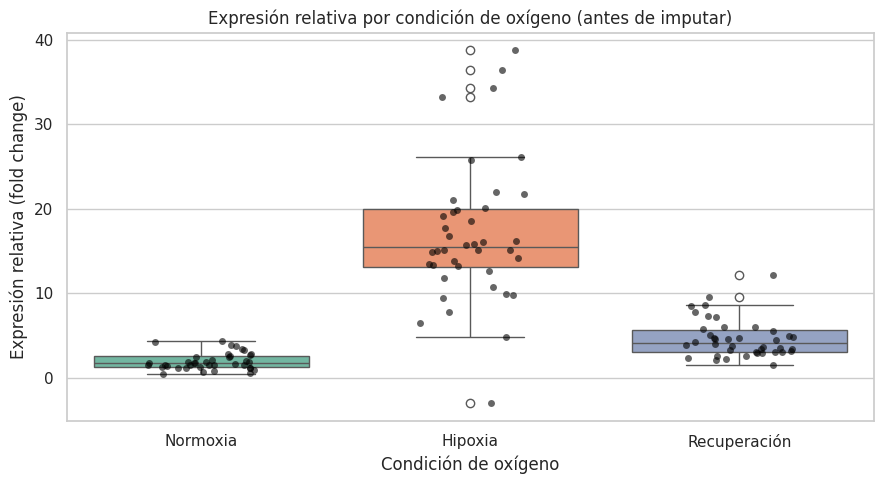

count    39.00
mean      1.96
std       1.01
min       0.48
25%       1.31
50%       1.71
75%       2.54
max       4.37
Name: expresion_relativa, dtype: float64


In [7]:
# -------------------------------------------------------------
# CELDA 6. BOXPLOT ANTES DE IMPUTAR
# -------------------------------------------------------------
# Revisamos la distribución de cada grupo antes de reemplazar el valor ausente.
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_limpio, x="condicion_oxigeno", y="expresion_relativa", hue="condicion_oxigeno", palette="Set2", legend=False)
sns.stripplot(data=df_limpio, x="condicion_oxigeno", y="expresion_relativa", alpha=0.6, color="black", jitter=0.2)
plt.title("Expresión relativa por condición de oxígeno (antes de imputar)")
plt.xlabel("Condición de oxígeno")
plt.ylabel("Expresión relativa (fold change)")
plt.tight_layout()
plt.show()

# Resumen del grupo que tiene el valor ausente (Normoxia).
print(df_limpio[df_limpio["condicion_oxigeno"] == "Normoxia"]["expresion_relativa"].describe().round(2))

## Imputación del valor ausente

In [8]:
# -------------------------------------------------------------
# CELDA 7. IMPUTACIÓN DEL VALOR AUSENTE
# -------------------------------------------------------------
# Guardamos cuál fila tiene el valor ausente, para dejar registro de la imputación.
faltantes = df_limpio["expresion_relativa"].isna()

# Calculamos la mediana de expresión relativa dentro de cada condición de oxígeno.
mediana_grupo = df_limpio.groupby("condicion_oxigeno")["expresion_relativa"].transform("median")

# Reemplazamos solo el valor ausente con la mediana de su grupo.
df_limpio["expresion_relativa"] = df_limpio["expresion_relativa"].fillna(mediana_grupo)

# Documentamos la imputación y verificamos el resultado.
print("Fila imputada:", df_limpio.loc[faltantes, "id_muestra"].tolist())
print("Valor imputado:", df_limpio.loc[faltantes, "expresion_relativa"].round(3).tolist())
print("Ausentes restantes en expresion_relativa:", df_limpio["expresion_relativa"].isna().sum())
print("Dimensiones:", df_limpio.shape)
print("Categorías:", df_limpio["condicion_oxigeno"].unique())

Fila imputada: ['GX010']
Valor imputado: [1.714]
Ausentes restantes en expresion_relativa: 0
Dimensiones: (120, 7)
Categorías: ['Normoxia' 'Hipoxia' 'Recuperación']


## Gráfico de caja (Boxplot) después de imputar

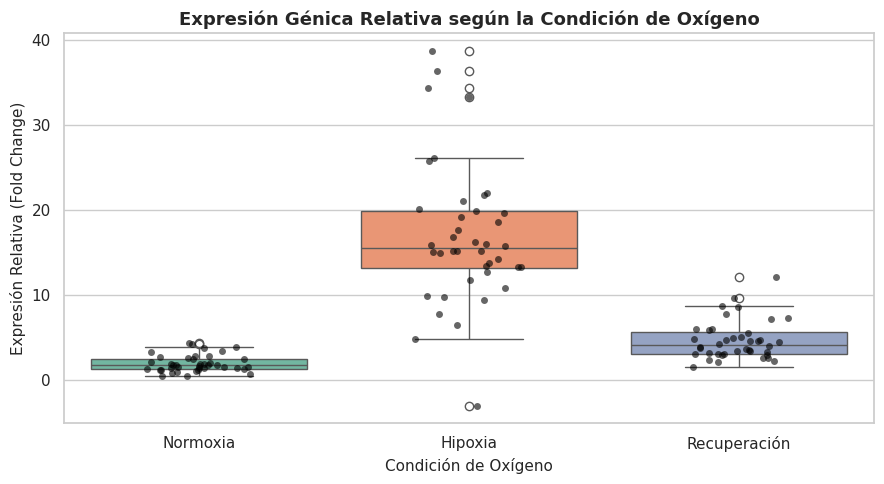

In [9]:
# -------------------------------------------------------------
# CELDA 8. GRÁFICO BOXPLOT DESPUÉS DE LA LIMPIEZA
# -------------------------------------------------------------
# Creamos la figura con el tamaño que queremos para el gráfico.
plt.figure(figsize=(9, 5))

# Dibujamos un boxplot por condición de oxígeno, para comparar la distribución de la expresión relativa ya con el dato imputado.
sns.boxplot(data=df_limpio, x="condicion_oxigeno", y="expresion_relativa", hue="condicion_oxigeno", palette="Set2", legend=False)
# Agregamos cada muestra como un punto negro, para ver todos los datos y no solo el resumen de la caja.
sns.stripplot(data=df_limpio, x="condicion_oxigeno", y="expresion_relativa", alpha=0.6, color="black", jitter=0.2)

# Ponemos título y nombres de los ejes, para que el gráfico se entienda solo.
plt.title("Expresión Génica Relativa según la Condición de Oxígeno", fontsize=13, fontweight='bold')
plt.xlabel("Condición de Oxígeno", fontsize=11)
plt.ylabel("Expresión Relativa (Fold Change)", fontsize=11)
# Ajustamos los márgenes y mostramos el gráfico.
plt.tight_layout()
plt.show()

## Atípicos por grupo mediante IQR

In [10]:
# -------------------------------------------------------------
# CELDA 9. ATÍPICOS POR GRUPO MEDIANTE IQR
# -------------------------------------------------------------
# Definimos una función reutilizable para detectar atípicos con la regla del IQR.
# Visto en Taller EDA Semana 3 (CELDA 13) y Repaso Parcial 1 (CELDA 10).
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    mascara = (serie < limite_inferior) | (serie > limite_superior)
    return mascara, q1, q3, iqr, limite_inferior, limite_superior

# Aplicamos la función a cada condición de oxígeno, igual que lo hace el boxplot.
for grupo in df_limpio["condicion_oxigeno"].unique():
    x = df_limpio.loc[df_limpio["condicion_oxigeno"] == grupo, "expresion_relativa"]
    mascara, q1, q3, iqr, li, ls = detectar_outliers_iqr(x)
    print(f"{grupo}: Q1={q1:.2f}, Q3={q3:.2f}, límites=({li:.2f}, {ls:.2f}), atípicos={mascara.sum()}")
    display(df_limpio.loc[x[mascara].index, ["id_muestra", "expresion_relativa"]])

Normoxia: Q1=1.32, Q3=2.49, límites=(-0.44, 4.25), atípicos=2


,id_muestra,expresion_relativa
18,GX019,4.368967
33,GX034,4.285539


Hipoxia: Q1=13.13, Q3=19.92, límites=(2.95, 30.10), atípicos=5


,id_muestra,expresion_relativa
47,GX048,34.328100
54,GX055,33.235951
55,GX056,36.383427
63,GX064,38.739465
75,GX076,-3.000000


Recuperación: Q1=3.08, Q3=5.60, límites=(-0.69, 9.37), atípicos=2


,id_muestra,expresion_relativa
88,GX089,9.618970
116,GX117,12.108493


## Revisión de valores fuera de rango

In [11]:
# -------------------------------------------------------------
# CELDA 10. REVISIÓN DE VALORES FUERA DE RANGO
# -------------------------------------------------------------
# Visto en Taller EDA Semana 3 (CELDAS 15 y 16): marcamos los valores fuera de un rango plausible para revisarlos y no los eliminamos automáticamente.
# Solo excluimos el valor que queda fuera del dominio de la variable (lo explicamos al final de esta celda).

# Creamos una columna para marcar los valores dudosos y dejar registro (supuesto del grupo).
df_limpio["valor_dudoso"] = False

# Definimos las condiciones de duda: viabilidad mayor a 100 % y expresión negativa.
via = df_limpio["viabilidad_pct"] > 100
neg = df_limpio["expresion_relativa"] < 0

# Detectamos los Ct atípicos del gen de referencia con la función de la CELDA 9, porque debería ser estable entre condiciones.
ct, q1, q3, iqr, li, ls = detectar_outliers_iqr(df_limpio["Ct_housekeeping"])

# Marcamos las filas que cumplen alguna condición y contamos cuántas hay de cada tipo.
df_limpio.loc[via | neg | ct, "valor_dudoso"] = True
print("viabilidad > 100:", via.sum(), "| expresion < 0:", neg.sum(),
      "| Ct_housekeeping atípico:", ct.sum())

# Mostramos las filas marcadas para revisarlas.
columnas = ["id_muestra", "condicion_oxigeno", "expresion_relativa",
            "Ct_housekeeping", "viabilidad_pct"]
display(df_limpio.loc[df_limpio["valor_dudoso"], columnas])

# Guardamos la fila con expresión negativa antes de excluirla, para dejar registro.
fila_excluida = df_limpio.loc[neg, ["id_muestra", "condicion_oxigeno", "expresion_relativa"]]
display(fila_excluida)

# Identificamos el grupo de la fila negativa para compararla, solo como apoyo, con las muestras de su mismo grupo.
grupo_negativa = df_limpio.loc[neg, "condicion_oxigeno"].iloc[0]

# Calculamos ΔCt (Ct del gen diana menos Ct del gen de referencia) como apoyo, no como criterio de exclusión. No lo vimos en clase (supuesto del grupo).
df_limpio["dCt"] = df_limpio["Ct_target"] - df_limpio["Ct_housekeeping"]

# Buscamos las muestras del mismo grupo con ΔCt parecido (±0.5) y miramos su expresión.
dct_negativa = df_limpio.loc[neg, "dCt"].iloc[0]
parecidas = df_limpio[(df_limpio["condicion_oxigeno"] == grupo_negativa) & (~neg) & ((df_limpio["dCt"] - dct_negativa).abs() <= 0.5)]
print("ΔCt de la fila negativa:", round(dct_negativa, 2))
print("Muestras del grupo con ΔCt parecido:", len(parecidas))
print("Su expresión: mediana =", round(parecidas["expresion_relativa"].median(), 2),
      "| mínimo =", round(parecidas["expresion_relativa"].min(), 2),
      "| máximo =", round(parecidas["expresion_relativa"].max(), 2))

# Excluimos solo esa fila: una cantidad relativa de expresión no puede ser negativa, así que el valor queda fuera del dominio de la variable, sin importar dónde caiga respecto al resto.
# El ΔCt solo muestra que el valor es inconsistente con sus Ct; no lo usamos para sustituirlo. Los demás valores dudosos se conservan marcados.
df_limpio = df_limpio[~neg].reset_index(drop=True)
print("Filas después de excluir el valor negativo:", df_limpio.shape[0])

viabilidad > 100: 2 | expresion < 0: 1 | Ct_housekeeping atípico: 1


,id_muestra,condicion_oxigeno,expresion_relativa,Ct_housekeeping,viabilidad_pct
24,GX025,Normoxia,0.508565,20.392657,101.362262
33,GX034,Normoxia,4.285539,21.255089,130.000000
75,GX076,Hipoxia,-3.000000,19.805775,78.697880
90,GX091,Recuperación,4.273277,55.000000,97.039517


,id_muestra,condicion_oxigeno,expresion_relativa
75,GX076,Hipoxia,-3.0


ΔCt de la fila negativa: -3.96
Muestras del grupo con ΔCt parecido: 27
Su expresión: mediana = 15.17 | mínimo = 9.39 | máximo = 21.79
Filas después de excluir el valor negativo: 119


## Tratamiento de GX091
GX091 (Recuperación) tiene un Ct_housekeeping de 55, fuera de lo esperable para un gen de referencia en qPCR. Lo conservamos y lo marcamos como dudoso porque su expresión relativa (4.27) cae dentro del dominio de la variable y es cercana a la mediana de su grupo (4.12), y no podemos demostrar que sea un error. Su efecto se evaluó en el análisis de sensibilidad (CELDA 21): al omitir los valores dudosos, la conclusión no cambió.

## Transformación log2(x)

In [12]:
# -------------------------------------------------------------
# CELDA 11. TRANSFORMACIÓN log2(x)
# -------------------------------------------------------------
# Transformamos la expresión relativa a log2(x), como menciona la guía del proyecto (Paso 8).
# Visto en Semana 10, CELDA 7 (np.log2); lo adaptamos a nuestra variable.
# No sumamos 1 porque, tras la limpieza, no hay valores iguales a cero (el mínimo es 0.48); la comparación con log2(x+1) está en la CELDA 28.
df_limpio["log2_expresion"] = np.log2(df_limpio["expresion_relativa"])

# Contamos cuántos valores no se pudieron transformar.
print("Valores sin transformar:", df_limpio["log2_expresion"].isna().sum())

Valores sin transformar: 0


## Shapiro-Wilk por grupo

In [13]:
# -------------------------------------------------------------
# CELDA 12. SHAPIRO-WILK POR GRUPO
# -------------------------------------------------------------
# Revisamos la normalidad de cada grupo con los datos originales y con los transformados.
# Visto en Taller 3, CELDA 15; lo adaptamos a nuestras variables.
for columna in ["expresion_relativa", "log2_expresion"]:
    print(columna)
    for grupo in df_limpio["condicion_oxigeno"].unique():
        valores = df_limpio.loc[df_limpio["condicion_oxigeno"] == grupo, columna].dropna()
        W, p = stats.shapiro(valores)
        print(f"  {grupo}: W = {W:.4f}, p = {p:.4f} (n = {len(valores)})")

# Interpretación: p > 0.05 significa que no hay evidencia para rechazar normalidad.

expresion_relativa
  Normoxia: W = 0.9200, p = 0.0077 (n = 40)
  Hipoxia: W = 0.9018, p = 0.0025 (n = 39)
  Recuperación: W = 0.8917, p = 0.0011 (n = 40)
log2_expresion
  Normoxia: W = 0.9719, p = 0.4119 (n = 40)
  Hipoxia: W = 0.9715, p = 0.4177 (n = 39)
  Recuperación: W = 0.9886, p = 0.9525 (n = 40)


## Prueba de Levene

In [14]:
# -------------------------------------------------------------
# CELDA 13. PRUEBA DE LEVENE
# -------------------------------------------------------------
# Comparamos si las varianzas de los tres grupos son parecidas con los datos originales y con los transformados.
# Visto en Taller 3, CELDA 17; lo adaptamos a nuestras variables.
for columna in ["expresion_relativa", "log2_expresion"]:
    x_normoxia = df_limpio.loc[df_limpio["condicion_oxigeno"] == "Normoxia", columna].dropna()
    x_hipoxia = df_limpio.loc[df_limpio["condicion_oxigeno"] == "Hipoxia", columna].dropna()
    x_recuperacion = df_limpio.loc[df_limpio["condicion_oxigeno"] == "Recuperación", columna].dropna()
    L, pL = stats.levene(x_normoxia, x_hipoxia, x_recuperacion)
    print(f"{columna}: Levene = {L:.4f}, p = {pL:.4g}")

expresion_relativa: Levene = 20.0466, p = 3.329e-08
log2_expresion: Levene = 0.6865, p = 0.5054


## Histogramas por grupo: original y log2(x)

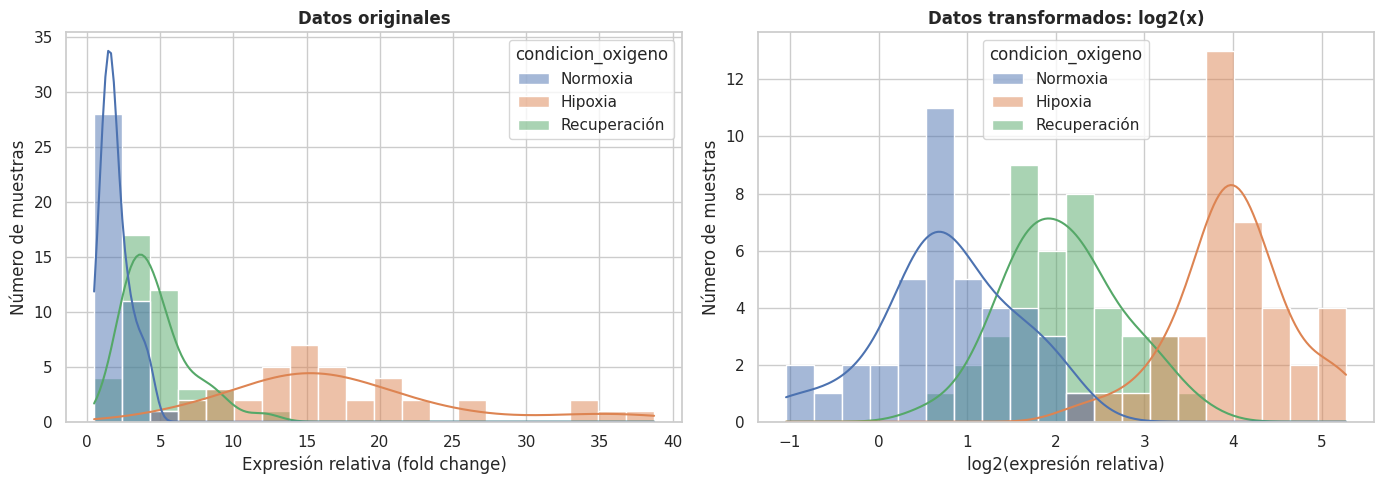

In [15]:
# -------------------------------------------------------------
# CELDA 14. HISTOGRAMAS POR GRUPO: ORIGINAL Y log2(x)
# -------------------------------------------------------------
# Fijamos el orden de los grupos para presentar siempre Normoxia (control) primero.
orden = ["Normoxia", "Hipoxia", "Recuperación"]

# Dibujamos dos paneles para comparar la forma de la distribución antes y después de transformar.
# Visto en Repaso Parcial 1, CELDA 13 y Taller EDA Semana 3, CELDA 22; lo adaptamos a dos escalas.
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_limpio, x="expresion_relativa", hue="condicion_oxigeno", hue_order=orden, bins=20, kde=True, alpha=0.5, ax=ejes[0])
ejes[0].set_title("Datos originales", fontsize=12, fontweight="bold")
ejes[0].set_xlabel("Expresión relativa (fold change)")
ejes[0].set_ylabel("Número de muestras")
sns.histplot(data=df_limpio, x="log2_expresion", hue="condicion_oxigeno", hue_order=orden, bins=20, kde=True, alpha=0.5, ax=ejes[1])
ejes[1].set_title("Datos transformados: log2(x)", fontsize=12, fontweight="bold")
ejes[1].set_xlabel("log2(expresión relativa)")
ejes[1].set_ylabel("Número de muestras")
plt.tight_layout()
plt.show()

## Interpretación de los histogramas
En la escala original, las tres condiciones tienen forma asimétrica, con cola hacia la derecha, y la dispersión crece con el nivel de expresión: Normoxia es compacta (su máximo es 4.37), Recuperación llega hasta 12.11 e Hipoxia hasta 38.74 (CELDA 15). Eso coincide con los resultados de Shapiro-Wilk (p entre 0.0011 y 0.0077, CELDA 12) y de Levene (p = 3.33e-08, CELDA 13), que indican que los datos originales no cumplen los supuestos del ANOVA.

Después de aplicar log2(x), las tres distribuciones se parecen más a una campana y tienen un ancho parecido: Shapiro-Wilk da p = 0.4119, 0.4177 y 0.9525, y Levene da p = 0.5054. Los centros quedan separados: las medias en escala log2 son 0.78 en Normoxia, 2.08 en Recuperación y 3.99 en Hipoxia (CELDA 26). Las barras de Normoxia y Recuperación se solapan en buena parte, y las de Hipoxia y Recuperación solo en una zona pequeña.

Un histograma muestra la forma de los datos, pero no sustituye las pruebas de supuestos.

## Medidas descriptivas por grupo

In [16]:
# -------------------------------------------------------------
# CELDA 15. MEDIDAS DESCRIPTIVAS POR GRUPO
# -------------------------------------------------------------
# Fijamos el orden de los grupos para presentar siempre Normoxia (control) primero.
orden = ["Normoxia", "Hipoxia", "Recuperación"]

# Calculamos las medidas descriptivas por grupo (adaptado de Repaso Parcial 1, CELDA 11, usando groupby).
resumen = df_limpio.groupby("condicion_oxigeno")["expresion_relativa"].agg(
    n="count", media="mean", mediana="median", DE="std",
    Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75),
    minimo="min", maximo="max"
).reindex(orden)

# Calculamos el IQR y el rango a partir de las columnas anteriores.
resumen["IQR"] = resumen["Q3"] - resumen["Q1"]
resumen["rango"] = resumen["maximo"] - resumen["minimo"]

# Mostramos la tabla con 2 decimales.
display(resumen.round(2))

,n,media,mediana,DE,Q1,Q3,minimo,maximo,IQR,rango
condicion_oxigeno,,,,,,,,,,
Normoxia,40,1.96,1.71,1.00,1.32,2.49,0.48,4.37,1.17,3.88
Hipoxia,39,17.48,15.75,7.83,13.29,19.97,4.83,38.74,6.68,33.91
Recuperación,40,4.69,4.12,2.28,3.08,5.60,1.50,12.11,2.52,10.61


## ANOVA de una vía sobre log2(x)

In [17]:
# -------------------------------------------------------------
# CELDA 16. ANOVA DE UNA VÍA SOBRE log2(x)
# -------------------------------------------------------------
# Creamos df_log: copia con los valores ya transformados.
df_log = df_limpio.dropna(subset=["log2_expresion"]).copy()
print("Filas en df_log:", df_log.shape[0])
print(df_log["condicion_oxigeno"].value_counts())

# Ajustamos un modelo lineal: log2_expresion depende del factor condicion_oxigeno.
# Visto en Taller 3, CELDA 24 y Repaso Parcial 1, CELDA 26.
modelo_anova = ols("log2_expresion ~ C(condicion_oxigeno)", data=df_log).fit()

# Generamos la tabla ANOVA y la mostramos.
tabla_anova = sm.stats.anova_lm(modelo_anova, typ=2)
display(tabla_anova)

Filas en df_log: 119
condicion_oxigeno
Normoxia        40
Recuperación    40
Hipoxia         39
Name: count, dtype: int64


,sum_sq,df,F,PR(>F)
C(condicion_oxigeno),205.800896,2.0,216.350331,7.196234e-40
Residual,55.171868,116.0,NaN,NaN


## Supuestos del ANOVA: residuos del modelo

Shapiro-Wilk de los residuos: W = 0.9850, p = 0.2095


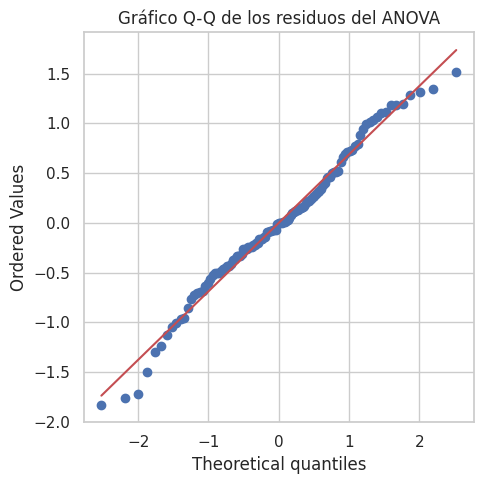

In [18]:
# -------------------------------------------------------------
# CELDA 17. SUPUESTOS DEL ANOVA: RESIDUOS DEL MODELO
# -------------------------------------------------------------
# Extraemos los residuos del modelo ANOVA (lo que el modelo no explica).
# Visto en Semana 8, CELDAS 8 a 10.
residuos = modelo_anova.resid

# Aplicamos Shapiro-Wilk a los residuos (visto en Taller 3, CELDA 15, aplicado a otra variable).
W_res, p_res = stats.shapiro(residuos)
print(f"Shapiro-Wilk de los residuos: W = {W_res:.4f}, p = {p_res:.4f}")

# Dibujamos el gráfico Q-Q de los residuos (stats.probplot, visto en Taller 3, CELDA 16).
plt.figure(figsize=(5, 5))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Gráfico Q-Q de los residuos del ANOVA")
plt.tight_layout()
plt.show()

## Tukey HSD y comparaciones contra el control

In [19]:
# -------------------------------------------------------------
# CELDA 18. TUKEY HSD Y COMPARACIONES CONTRA EL CONTROL
# -------------------------------------------------------------
# Aplicamos Tukey a la expresión transformada entre los tres grupos (visto en Taller 3, CELDA 26).
tukey = pairwise_tukeyhsd(
    endog=df_log["log2_expresion"],
    groups=df_log["condicion_oxigeno"],
    alpha=0.05
)
print(tukey)

# Convertimos la tabla de Tukey en un DataFrame para poder filtrarla (supuesto del grupo, no visto en clase).
tabla_tukey = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])

# Nos quedamos solo con los pares que incluyen a Normoxia (el control).
contra_control = tabla_tukey[(tabla_tukey["group1"] == "Normoxia") | (tabla_tukey["group2"] == "Normoxia")]
display(contra_control)

    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1     group2    meandiff p-adj  lower   upper  reject
-----------------------------------------------------------
 Hipoxia     Normoxia  -3.2112   0.0 -3.5796 -2.8427   True
 Hipoxia Recuperación  -1.9124   0.0 -2.2809 -1.5439   True
Normoxia Recuperación   1.2988   0.0  0.9327  1.6649   True
-----------------------------------------------------------


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Hipoxia,Normoxia,-3.2112,0.0,-3.5796,-2.8427,True
2,Normoxia,Recuperación,1.2988,0.0,0.9327,1.6649,True


## Eta cuadrado ($\eta^2$)

In [20]:
# -------------------------------------------------------------
# CELDA 19. ETA CUADRADO
# -------------------------------------------------------------
# Extraemos la suma de cuadrados del factor condición de oxígeno (visto en Taller 3, CELDA 25 y Semana 8, CELDA 13).
ss_grupo = tabla_anova.loc["C(condicion_oxigeno)", "sum_sq"]

# Sumamos todas las sumas de cuadrados de la tabla ANOVA.
ss_total = tabla_anova["sum_sq"].sum()

# Calculamos eta cuadrado: qué parte de la variación se asocia con la condición.
eta2 = ss_grupo / ss_total

# Mostramos el resultado.
print("Eta cuadrado (η²) =", round(eta2, 3))

Eta cuadrado (η²) = 0.789


## Prueba de Kruskal-Wallis

In [21]:
# -------------------------------------------------------------
# CELDA 20. KRUSKAL-WALLIS
# -------------------------------------------------------------
# Extraemos la expresión relativa de cada grupo (datos originales).
e_normoxia = df_limpio.loc[df_limpio["condicion_oxigeno"] == "Normoxia", "expresion_relativa"]
e_hipoxia = df_limpio.loc[df_limpio["condicion_oxigeno"] == "Hipoxia", "expresion_relativa"]
e_recuperacion = df_limpio.loc[df_limpio["condicion_oxigeno"] == "Recuperación", "expresion_relativa"]

# Ejecutamos la prueba global (visto en Repaso Parcial 1, CELDA 28 y Taller 3, CELDA 27).
H, p_kw = stats.kruskal(e_normoxia, e_hipoxia, e_recuperacion)

# Mostramos el estadístico H y el p-valor.
print("H =", round(H, 4))
print("p =", format(p_kw, ".6g"))

H = 93.47
p = 5.04959e-21


## Análisis de sensibilidad

In [22]:
# -------------------------------------------------------------
# CELDA 21. ANÁLISIS DE SENSIBILIDAD
# -------------------------------------------------------------
# Visto en Semana 7 (CELDA 29): repetimos el análisis sin las observaciones marcadas para ver cuánto cambia la conclusión; no reemplaza el análisis principal.
# Definimos una función que repite el ANOVA sobre log2(x) y Kruskal-Wallis con cualquier subconjunto de datos.
def pruebas_subconjunto(datos):
    d = datos.dropna(subset=["expresion_relativa"]).copy()
    d["log2_expresion"] = np.log2(d["expresion_relativa"])
    modelo = ols("log2_expresion ~ C(condicion_oxigeno)", data=d).fit()
    tabla = sm.stats.anova_lm(modelo, typ=2)
    grupos = [d.loc[d["condicion_oxigeno"] == g, "expresion_relativa"] for g in orden]
    H, p_kw = stats.kruskal(*grupos)
    return [len(d), round(tabla["F"].iloc[0], 2), f"{tabla['PR(>F)'].iloc[0]:.2e}", round(H, 2), f"{p_kw:.2e}"]

# Volvemos a dejar vacío el valor que imputamos (GX010) para crear la versión sin imputar.
sin_imputar = df_limpio.copy()
sin_imputar.loc[sin_imputar["id_muestra"] == "GX010", "expresion_relativa"] = np.nan

# Marcamos los atípicos por IQR dentro de cada grupo, con la función de la CELDA 9.
es_atipico = pd.Series(False, index=df_limpio.index)
for grupo in orden:
    x = df_limpio.loc[df_limpio["condicion_oxigeno"] == grupo, "expresion_relativa"]
    es_atipico[x[detectar_outliers_iqr(x)[0]].index] = True

# Armamos los escenarios (supuesto del grupo).
escenarios = {
    "Base de 119 filas (principal)": df_limpio,
    "Sin imputar (GX010 omitido)": sin_imputar,
    "Sin atípicos IQR": df_limpio[~es_atipico],
    "Sin valores dudosos": df_limpio[~df_limpio["valor_dudoso"]],
}

# Calculamos las dos pruebas en cada escenario y mostramos una sola tabla.
filas = [[nombre] + pruebas_subconjunto(datos) for nombre, datos in escenarios.items()]
tabla_sens = pd.DataFrame(filas, columns=["Escenario", "n", "F (ANOVA log2)", "p ANOVA", "H (Kruskal-Wallis)", "p Kruskal"])
display(tabla_sens)

,Escenario,n,F (ANOVA log2),p ANOVA,H (Kruskal-Wallis),p Kruskal
0,Base de 119 filas (principal),119,216.35,7.20e-40,93.47,5.05e-21
1,Sin imputar (GX010 omitido),118,212.14,2.57e-39,92.58,7.87e-21
2,Sin atípicos IQR,111,236.53,3.45e-40,88.90,4.95e-20
3,Sin valores dudosos,116,224.38,4.46e-40,91.92,1.10e-20


## Interpretación del análisis de sensibilidad
Repetimos el análisis en cuatro escenarios para ver si la conclusión depende de una decisión de limpieza. En los cuatro, el ANOVA sobre log2(x) y Kruskal-Wallis dieron resultados muy parecidos: F entre 212.14 y 236.53, H entre 88.90 y 93.47, y todos los p menores que 1e-19.

- **Sin imputar (n = 118):** al omitir GX010, el resultado casi no cambia (F = 212.14 frente a 216.35 en la base principal).
- **Sin atípicos IQR (n = 111):** F sube a 236.53, porque al quitar los valores extremos se reduce la variación dentro de los grupos. H baja un poco (88.90).
- **Sin valores dudosos (n = 116):** esta fila omite GX025, GX034 y GX091, y el resultado sigue siendo F = 224.38 y H = 91.92.

Ninguna decisión de limpieza cambia la conclusión. Este análisis solo muestra que el resultado es robusto, no reemplaza el análisis principal ni justifica por sí solo cada decisión.

## Z-score por grupo

In [23]:
# -------------------------------------------------------------
# CELDA 22. Z-SCORE POR GRUPO
# -------------------------------------------------------------
# Calculamos el z-score de cada muestra dentro de su grupo: cuántas desviaciones estándar está de la media del grupo.
# Visto en Semana 10, CELDA 9 (z-score por gen); lo adaptamos para calcularlo por grupo.
df_limpio["z_expresion"] = df_limpio.groupby("condicion_oxigeno")["expresion_relativa"].transform(
    lambda x: (x - x.mean()) / x.std(ddof=0)
)

# Contamos cuántas muestras superan 2 y 3 desviaciones estándar (regla de la campana de Gauss).
print("Muestras con |z| > 2:", int((df_limpio["z_expresion"].abs() > 2).sum()))
print("Muestras con |z| > 3:", int((df_limpio["z_expresion"].abs() > 3).sum()))

# Mostramos las muestras con |z| > 2, de mayor a menor.
extremas = df_limpio.loc[df_limpio["z_expresion"].abs() > 2, ["id_muestra", "condicion_oxigeno", "expresion_relativa", "z_expresion"]]
display(extremas.sort_values("z_expresion", key=lambda s: s.abs(), ascending=False).round(2))

Muestras con |z| > 2: 8
Muestras con |z| > 3: 1


,id_muestra,condicion_oxigeno,expresion_relativa,z_expresion
115,GX117,Recuperación,12.11,3.30
63,GX064,Hipoxia,38.74,2.75
55,GX056,Hipoxia,36.38,2.45
18,GX019,Normoxia,4.37,2.45
33,GX034,Normoxia,4.29,2.36
87,GX089,Recuperación,9.62,2.19
47,GX048,Hipoxia,34.33,2.18
54,GX055,Hipoxia,33.24,2.04


## Resumen del control de calidad

In [24]:
# -------------------------------------------------------------
# CELDA 23. RESUMEN DEL CONTROL DE CALIDAD
# -------------------------------------------------------------
# Contamos cada paso del control de calidad a partir de los DataFrames que ya tenemos.
n_inicial = df.shape[0]
duplicados_eliminados = int(df.duplicated(subset=["id_muestra"]).sum())
ausentes_imputados = int(df["expresion_relativa"].isna().sum())
filas_excluidas = fila_excluida.shape[0]
n_final = df_limpio.shape[0]

# Contamos los atípicos por IQR dentro de cada grupo, con la función de la CELDA 9.
atipicos = 0
for grupo in df_limpio["condicion_oxigeno"].unique():
    x = df_limpio.loc[df_limpio["condicion_oxigeno"] == grupo, "expresion_relativa"]
    atipicos += int(detectar_outliers_iqr(x)[0].sum())

# Contamos los valores dudosos que quedaron marcados.
dudosos = int(df_limpio["valor_dudoso"].sum())

# Armamos una tabla que deja registro de cada decisión (supuesto del grupo).
resumen_qc = pd.DataFrame({
    "Paso": ["Filas del CSV original", "Duplicados eliminados", "Valores ausentes imputados",
             "Filas excluidas (expresión negativa)", "Filas finales para el análisis",
             "Atípicos por IQR (marcados)", "Valores dudosos (marcados)"],
    "Cantidad": [n_inicial, duplicados_eliminados, ausentes_imputados, filas_excluidas, n_final, atipicos, dudosos],
    "Decisión": ["-", "Se dejó una copia de cada uno", "Mediana del grupo", "Un fold change no puede ser negativo",
                 "-", "Se conservan", "Se conservan"]
})
display(resumen_qc)

,Paso,Cantidad,Decisión
0,Filas del CSV original,122,-
1,Duplicados eliminados,2,Se dejó una copia de cada uno
2,Valores ausentes imputados,1,Mediana del grupo
3,Filas excluidas (expresión negativa),1,Un fold change no puede ser negativo
4,Filas finales para el análisis,119,-
5,Atípicos por IQR (marcados),8,Se conservan
6,Valores dudosos (marcados),3,Se conservan


## Tamaño de la diferencia contra el control

In [25]:
# -------------------------------------------------------------
# CELDA 24. TAMAÑO DE LA DIFERENCIA CONTRA EL CONTROL
# -------------------------------------------------------------
# Calculamos la mediana de cada grupo y tomamos la de Normoxia como referencia.
medianas = df_limpio.groupby("condicion_oxigeno")["expresion_relativa"].median()
mediana_control = medianas["Normoxia"]

# Comparamos cada tratamiento contra el control con la diferencia y el cociente de medianas.
for grupo in ["Hipoxia", "Recuperación"]:
    diferencia = medianas[grupo] - mediana_control
    cociente = medianas[grupo] / mediana_control
    print(f"{grupo} vs Normoxia: diferencia de medianas = {diferencia:.2f} | cociente = {cociente:.2f} veces")

Hipoxia vs Normoxia: diferencia de medianas = 14.04 | cociente = 9.19 veces
Recuperación vs Normoxia: diferencia de medianas = 2.41 | cociente = 2.40 veces


## Figura final con los valores marcados

marca
Normal          109
Atípico IQR       7
Valor dudoso      3
Name: count, dtype: int64


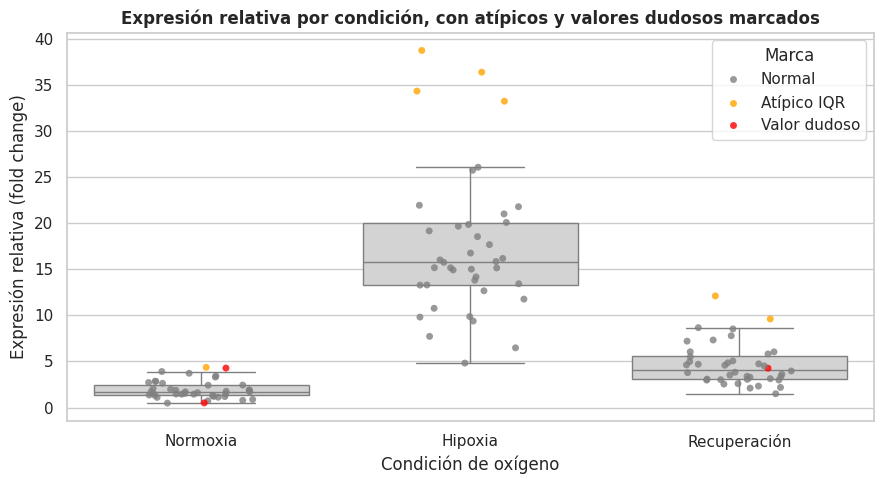

In [26]:
# -------------------------------------------------------------
# CELDA 25. FIGURA FINAL: DISTRIBUCIÓN CON LOS VALORES MARCADOS
# -------------------------------------------------------------
# Fijamos el orden de los grupos para presentar siempre Normoxia (control) primero.
orden = ["Normoxia", "Hipoxia", "Recuperación"]

# Marcamos los atípicos por IQR dentro de cada grupo, con la función de la CELDA 9.
es_atipico_figura = pd.Series(False, index=df_limpio.index)
for grupo in orden:
    x = df_limpio.loc[df_limpio["condicion_oxigeno"] == grupo, "expresion_relativa"]
    es_atipico_figura[x[detectar_outliers_iqr(x)[0]].index] = True

# Clasificamos cada muestra: los valores dudosos tienen prioridad sobre los atípicos.
df_limpio["marca"] = "Normal"
df_limpio.loc[es_atipico_figura, "marca"] = "Atípico IQR"
df_limpio.loc[df_limpio["valor_dudoso"], "marca"] = "Valor dudoso"
print(df_limpio["marca"].value_counts())

# Dibujamos el boxplot sin sus puntos propios y encima los puntos de cada muestra con su marca.
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_limpio, x="condicion_oxigeno", y="expresion_relativa", order=orden, color="lightgray", showfliers=False)
sns.stripplot(data=df_limpio, x="condicion_oxigeno", y="expresion_relativa", order=orden, hue="marca",
              hue_order=["Normal", "Atípico IQR", "Valor dudoso"],
              palette={"Normal": "gray", "Atípico IQR": "orange", "Valor dudoso": "red"}, jitter=0.2, alpha=0.8)
plt.title("Expresión relativa por condición, con atípicos y valores dudosos marcados", fontsize=12, fontweight="bold")
plt.xlabel("Condición de oxígeno")
plt.ylabel("Expresión relativa (fold change)")
plt.legend(title="Marca")
plt.tight_layout()
plt.show()

## Interpretación de la figura final
La mediana más alta es la de Hipoxia (15.75), la de Recuperación queda en medio (4.12) y la más baja es la de Normoxia (1.71) (CELDA 15). La caja de Hipoxia es la más ancha (IQR de 6.68, contra 2.52 en Recuperación y 1.17 en Normoxia), así que es la condición más variable.

La figura marca 7 atípicos por IQR (naranja) y 3 valores dudosos (rojo). Son 8 atípicos en total, pero GX034 también es un valor dudoso y la figura lo muestra como dudoso. Un atípico estadístico es un valor poco frecuente, no necesariamente un error, por eso se marcaron y no se eliminaron. GX076 (expresión = -3.0) no aparece porque se excluyó antes (CELDA 10).

El valor más bajo de Hipoxia (4.83) es mayor que el más alto de Normoxia (4.37). Esto describe estos datos y no es una prueba. Hipoxia y Recuperación sí se solapan en sus valores individuales (Recuperación llega hasta 12.11).

## Tabla resumen para la interpretación final

In [27]:
# -------------------------------------------------------------
# CELDA 26. TABLA RESUMEN PARA LA INTERPRETACIÓN FINAL
# -------------------------------------------------------------
# Fijamos el orden de los grupos para presentar siempre Normoxia (control) primero.
orden = ["Normoxia", "Hipoxia", "Recuperación"]

# Calculamos un resumen de la expresión relativa original con mediana y cuartiles (adaptado de Taller 3, CELDA 28).
tabla_final_original = (
    df_limpio.groupby("condicion_oxigeno")["expresion_relativa"]
    .agg(n="count", mediana="median", q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75))
    .reindex(orden)
    .round(2)
)

# Calculamos un resumen de la expresión transformada con media y desviación estándar.
tabla_final_log2 = (
    df_log.groupby("condicion_oxigeno")["log2_expresion"]
    .agg(n="count", media="mean", desviacion_estandar="std")
    .reindex(orden)
    .round(2)
)

# Mostramos ambas tablas.
print("EXPRESIÓN RELATIVA (datos originales)")
display(tabla_final_original)
print("EXPRESIÓN EN ESCALA log2(x)")
display(tabla_final_log2)

# Identificamos el grupo con mayor media transformada (adaptado de Taller EDA Semana 3, CELDA 28).
medias_ordenadas = df_log.groupby("condicion_oxigeno")["log2_expresion"].mean().sort_values(ascending=False)
print("Grupo con mayor media en escala log2:", medias_ordenadas.index[0])
print(medias_ordenadas.round(2))

EXPRESIÓN RELATIVA (datos originales)


,n,mediana,q1,q3
condicion_oxigeno,,,,
Normoxia,40,1.71,1.32,2.49
Hipoxia,39,15.75,13.29,19.97
Recuperación,40,4.12,3.08,5.60


EXPRESIÓN EN ESCALA log2(x)


,n,media,desviacion_estandar
condicion_oxigeno,,,
Normoxia,40,0.78,0.76
Hipoxia,39,3.99,0.64
Recuperación,40,2.08,0.65


Grupo con mayor media en escala log2: Hipoxia
condicion_oxigeno
Hipoxia         3.99
Recuperación    2.08
Normoxia        0.78
Name: log2_expresion, dtype: float64


## Reproducibilidad: versiones utilizadas

In [28]:
# -------------------------------------------------------------
# CELDA 27. REPRODUCIBILIDAD: VERSIONES UTILIZADAS
# -------------------------------------------------------------
# Importamos los módulos que nos dan la información del entorno.
import sys
import platform
import scipy
import statsmodels
import matplotlib

# Mostramos las versiones de Python y de cada librería para que el análisis se pueda reproducir.
print("Python:", sys.version.split()[0], "|", platform.platform())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("statsmodels:", statsmodels.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

Python: 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39
NumPy: 2.4.6
pandas: 2.2.3
SciPy: 1.16.3
statsmodels: 0.15.0
Matplotlib: 3.10.0
Seaborn: 0.13.2


## Comparación de transformaciones: log2(x) y log2(x+1)
Evidencia para justificar la transformación elegida: comparamos los supuestos del ANOVA en la escala original, en log2(x) y en log2(x+1).


In [29]:
# -------------------------------------------------------------
# CELDA 28. COMPARACIÓN DE TRANSFORMACIONES: log2(x) Y log2(x+1)
# -------------------------------------------------------------
# Reunimos la variable original y las dos transformaciones que vamos a comparar.
transformaciones = {
    "Original": df_limpio["expresion_relativa"],
    "log2(x) (la que usamos)": df_limpio["log2_expresion"],
    "log2(x+1)": np.log2(df_limpio["expresion_relativa"] + 1),
}

# Para cada escala calculamos los supuestos del modelo: normalidad por grupo, homogeneidad y normalidad de los residuos.
filas = []
for nombre, y in transformaciones.items():
    datos = df_limpio.assign(y=y)
    p_shapiro = [stats.shapiro(datos.loc[datos["condicion_oxigeno"] == grupo, "y"])[1] for grupo in orden]
    L, p_levene = stats.levene(*[datos.loc[datos["condicion_oxigeno"] == grupo, "y"] for grupo in orden])
    modelo = ols("y ~ C(condicion_oxigeno)", data=datos).fit()
    p_residuos = stats.shapiro(modelo.resid)[1]
    filas.append([nombre, f"{min(p_shapiro):.4f}", f"{p_levene:.4g}", f"{p_residuos:.4g}"])

# Mostramos una sola tabla para decidir qué escala se ajusta mejor al ANOVA.
display(pd.DataFrame(filas, columns=["Escala", "Shapiro: p mínimo entre grupos", "Levene: p", "Shapiro de residuos: p"]))


,Escala,Shapiro: p mínimo entre grupos,Levene: p,Shapiro de residuos: p
0,Original,0.0011,3.329e-08,1.778e-11
1,log2(x) (la que usamos),0.4119,0.5054,0.2095
2,log2(x+1),0.4726,0.5938,0.4535


## Estrategia preliminar de análisis

**1. ¿Cuál es nuestra pregunta?**
¿Existe diferencia en la expresión relativa del gen diana entre normoxia, hipoxia y recuperación? Si existe, ¿entre qué condiciones se presenta?

**2. Variable dependiente:**
La expresión relativa (fold change), cuantitativa continua y positiva. Se analiza en escala log2(x).

**3. Variable independiente:**
La condición de oxígeno, cualitativa nominal con tres grupos: Normoxia (control), Hipoxia y Recuperación. Partimos de 122 filas. Eliminamos 2 duplicados exactos (GX019 y GX082), imputamos 1 valor ausente (GX010) con la mediana de su grupo y excluimos GX076 (expresión = -3.0): una cantidad relativa de expresión no puede ser negativa, por lo que el valor queda fuera del dominio de la variable; no lo sustituimos y lo conservamos en la base original. Quedaron 119 filas: 40 en Normoxia, 39 en Hipoxia y 40 en Recuperación.

**4. Tipo de variables:**
Dependiente cuantitativa continua e independiente cualitativa nominal. Ct_target y viabilidad_pct no entran en las pruebas; solo apoyan el control de calidad.

**5. Grupos comparados:**
Tres grupos independientes, comparados entre sí por pares (Normoxia-Hipoxia, Normoxia-Recuperación e Hipoxia-Recuperación).

**6. Supuestos verificados:**
En la escala original no: Shapiro-Wilk da p = 0.0077 (Normoxia), 0.0025 (Hipoxia) y 0.0011 (Recuperación), y Levene da p = 3.33e-08. En log2(x) sí: Shapiro da p = 0.41, 0.42 y 0.95, Levene da p = 0.51 y los residuos del modelo tampoco rechazan normalidad (p = 0.21). También comparamos log2(x+1) (CELDA 28): ambas escalas cumplen los supuestos y elegimos log2(x) porque, tras la limpieza, no hay valores iguales a cero y sus diferencias se leen como razones. La independencia de las réplicas es un supuesto del diseño que no se puede comprobar con estos datos.

**7. Método seleccionado:**
ANOVA de una vía sobre log2(x) (F(2, 116) = 216.35, p = 7.20e-40), con Tukey HSD para saber entre qué pares hay diferencia y η² = 0.79 para el tamaño del efecto. Kruskal-Wallis sobre los datos originales (H = 93.47, p = 5.05e-21) y un análisis de sensibilidad (con y sin imputación, atípicos y valores dudosos) respaldan que la conclusión no depende de esas decisiones.

## Interpretación

## Interpretación estadística
- **Supuestos.** Los datos originales no cumplieron los supuestos del ANOVA (Shapiro-Wilk p entre 0.0011 y 0.0077; Levene p = 3.33e-08). En escala log2(x) sí los cumplieron (Shapiro-Wilk p = 0.4119, 0.4177 y 0.9525; Levene p = 0.5054; residuos del modelo W = 0.9850, p = 0.2095). Por eso el análisis principal se hizo sobre log2(x).
- **ANOVA (CELDA 16).** F(2, 116) = 216.35 y p = 7.20e-40. Los datos son muy poco compatibles con H₀ (la media de la expresión, en escala log2, es igual en las tres condiciones). Hay evidencia de que al menos una condición difiere, pero el ANOVA no dice cuál.
- **Tukey (CELDA 18).** Los tres pares difieren, con p ajustado menor que 0.001 y ningún intervalo que incluya el 0. En unidades log2, Hipoxia supera a Normoxia por 3.21 (IC 95 %: 2.84 a 3.58), Hipoxia supera a Recuperación por 1.91 (1.54 a 2.28) y Recuperación supera a Normoxia por 1.30 (0.93 a 1.66). La tabla de statsmodels resta "grupo 2 menos grupo 1", por eso muestra los signos invertidos para Hipoxia.
- **Tamaño de la diferencia.** η² = 0.789 (CELDA 19): cerca del 79 % de la variación en escala log2 se asocia con la condición de oxígeno. Las medianas de Hipoxia y Recuperación equivalen a 9.19 y 2.40 veces la de Normoxia (CELDA 24), y la de Hipoxia a 3.82 veces la de Recuperación (CELDA 15).

## Interpretación biológica
En este conjunto de datos simulado, la expresión del gen diana fue más alta en Hipoxia, intermedia en Recuperación y más baja en Normoxia. Comparar Hipoxia con Recuperación aporta algo que no se ve al comparar cada una solo con el control: al restablecer el oxígeno, la expresión baja (1.91 unidades log2 respecto a Hipoxia), pero no vuelve al nivel de Normoxia, que sigue 1.30 unidades por debajo de Recuperación. Es decir, la reversión es parcial.

No se conoce qué gen es ni el mecanismo, y el diseño no permite afirmar que la hipoxia causó el cambio.

## Significancia e importancia biológica
Un p-valor muy pequeño indica que la diferencia es difícil de explicar por azar, pero no dice qué tan grande es. La magnitud la dan η² y los cocientes de medianas. Si la diferencia es relevante biológicamente depende del gen, que aquí no se conoce.

## Robustez del resultado
Kruskal-Wallis, sobre los datos originales, llega a la misma conclusión (H = 93.47, p = 5.05e-21; CELDA 20). Al repetir el análisis sin el valor imputado, sin los atípicos y sin los valores dudosos, F varió entre 212.14 y 236.53, H entre 88.90 y 93.47, y todos los p fueron menores que 1e-19 (CELDA 21). Según el z-score, 8 muestras superan 2 desviaciones estándar y solo GX117 supera 3 (z = 3.30; CELDA 22). Este análisis complementa, pero no reemplaza, la justificación de cada decisión de limpieza, que se basó en la definición y el dominio de las variables.

## Conclusiones
1. La expresión relativa del gen diana difiere entre normoxia, hipoxia y recuperación (ANOVA sobre log2(x): F(2, 116) = 216.35, p = 7.20e-40). Hay evidencia en contra de H₀ en este conjunto de datos simulado.
2. Los tres pares difieren (Tukey, p ajustado < 0.001): Hipoxia es la condición con mayor expresión, Recuperación queda en medio y Normoxia tiene la menor.
3. La diferencia es grande: la mediana de Hipoxia fue 9.19 veces la de Normoxia y la de Recuperación 2.40 veces; η² = 0.789.
4. Al restablecer el oxígeno, la expresión baja respecto a Hipoxia pero no regresa al nivel de Normoxia (reversión parcial).
5. La conclusión se mantuvo al omitir el valor imputado, los atípicos y los valores dudosos, y con Kruskal-Wallis.

## Limitaciones
- Los datos son ficticios o simulados: las conclusiones valen solo para este conjunto de datos.
- No se sabe qué gen es, por lo que no se le atribuye una función específica ni un mecanismo.
- La independencia de las réplicas es un supuesto del diseño y no puede comprobarse con estos datos.
- El conjunto de datos no informa cuánto duró la hipoxia ni la recuperación.
- Un valor de Normoxia (GX010) se imputó con la mediana de su grupo (1.714). Una imputación única no refleja la incertidumbre del dato; por eso se evaluó su efecto en el análisis de sensibilidad.
- GX076 (expresión = -3.0) se excluyó porque queda fuera del dominio de la variable. No sabemos qué causó ese valor y no se sustituyó.
- viabilidad_pct no tiene definición confirmada. Se interpretó como porcentaje de células vivas (0 a 100 %), por eso GX025 y GX034 se marcaron como dudosos.
- GX091 tiene un Ct del gen de referencia de 55, fuera de lo esperable en qPCR. Se conservó porque su expresión relativa (4.27) es cercana a la mediana de su grupo, pero ese Ct merece revisión.
- La expresión relativa ya venía como fold change y no se recalculó a partir de los Ct.
- Se eligió log2(x) frente a log2(x+1) porque no hay ceros; ambas escalas cumplieron los supuestos (CELDA 28).

## Declaración de uso de herramientas de inteligencia artificial

Para la elaboración de este proyecto se utilizó inteligencia artificial generativa como apoyo académico. Cada integrante declara a continuación qué herramienta usó y para qué.

**David Donoso.** Utilizó Claude (Anthropic, Sonnet 5.5) entre el 7 de octubre y el 3 de noviembre de 2026 como herramienta de apoyo y de redacción de borradores. Las decisiones, la verificación y la revisión final fueron suyas, como se detalla a continuación:

- **Código.** Consultó los cuadernos proporcionados por la profesora y la documentación de NumPy y pandas, y le pidió a Claude generar, ajustar y revisar fragmentos de código de las celdas. Contrastó cada celda con los procedimientos vistos en clase, la ejecutó en Google Colab, identificó los errores de ejecución y corrigió lo que no coincidía con los cuadernos de la profesora.
- **Decisiones de limpieza y transformación.** Usó Claude para explorar alternativas sobre duplicados, valores ausentes, atípicos, la muestra GX076 y las transformaciones log2(x) y log2(x+1), y para comparar sus implicaciones. Después contrastó esas alternativas con los cuadernos del curso, consultó a la profesora y propuso al grupo usar log2(x). Las decisiones finales fueron del grupo, con base en las respuestas escritas de la profesora.
- **Fuentes.** Pidió a Claude orientación para formular búsquedas y localizó artículos académicos, que leyó completos y verificó. De Rieu y Powers (2009) tomó como referencia la transformación log2 de las cantidades relativas normalizadas (log2(NRQ)) antes del ANOVA, y el uso de Kruskal-Wallis y de la omisión de muestras influyentes como análisis de apoyo.
- **Documentación.** Revisó el historial de commits del repositorio de GitHub y reconstruyó con él la evolución del cuaderno para el registro del procesamiento celda por celda. Claude redactó borradores de la metodología, del registro y de los apuntes de defensa, que él revisó, corrigió y completó.
- **Interpretación.** Claude redactó borradores de las interpretaciones por figura, de la sección Interpretación, de las Conclusiones y de las Limitaciones, con cifras tomadas de las salidas de las celdas. Él los revisó contra los resultados del cuaderno y contra la metodología, y los reescribió con sus propias palabras junto con el grupo, conservando las cifras de las salidas.
- **Verificación.** Claude realizó ejecuciones de referencia del código. Él las contrastó con su propia ejecución independiente en Colab, verificando las cifras y el funcionamiento de las celdas sin asumir las salidas de la IA como definitivas.

**Yahelys.** Usó Claude (Sonnet 5.5) hacia el 21 de octubre de 2026  para elaborar tres celdas: Shapiro-Wilk, Levene e histogramas.
- La primera versión generada no coincidía con el cuaderno, así que la modificó y la ajustó al estilo de los cuadernos de la profesora (las celdas dadas por claude estaban generadas a partir del conocimiento de la ia pero fueron modificadas utilizando los cuadernos de la profe para una mejor aplicacion de las mismas).

**Jamel.** Usó Gemini (Gemini 2.5 Flash) el 7 de octubre de 2026 para las celdas 5 y 6 (copia de trabajo, categorías y duplicados, y gráfico de caja antes de imputar).
- Las demás celdas y textos los trabajó con Claude (Anthropic, Sonnet 5.5): la figura final, la revisión de lo que faltaba en el cuaderno, los títulos y comentarios de las celdas (21 de octubre) y los textos iniciales (portada, problema, pregunta, hipótesis, variables y estrategia preliminar, 25 de octubre).
- Su Claude se conectó varias veces al Drive y al Colab, y luego dejó de usarse.

**Francia.**  Usó Meta AI (WhatsApp; versión no recordada) el primer día del proyecto para obtener puntos de partida: posibles preguntas, variables e hipótesis. Después investigó esos puntos por su cuenta y los discutió con el grupo. No volvió a usar la herramienta.

**Liz.** [Completar: indicar si usó IA para el borrador de la pregunta, la hipótesis, la introducción o el informe, o que no usó herramientas de IA.]

**Ashly.** [Completar cuando confirme su participación.]

Los integrantes del grupo asumimos la responsabilidad de revisar y verificar las sugerencias recibidas, contrastarlas con los contenidos de BIO 218 y comprobar la coherencia entre los procedimientos, los resultados y las conclusiones. Durante el trabajo se detectaron y corrigieron errores y criterios desactualizados de la IA, por ejemplo un criterio previo de exclusión que se reemplazó tras la respuesta escrita de la profesora.

Las decisiones metodológicas, la interpretación de los análisis y la presentación de los resultados son responsabilidad académica de los integrantes del equipo. No se presentaron resultados, referencias o verificaciones generadas por IA como evidencia empírica sin su comprobación.